# Cheltenham Analysis

# Data Locations

This Jupyter notebook is in "OneDrive - Turftrax\Documents - Tech Support\Processes\000020-data_science_analysis\010-cheltenham_2024".

In [2]:
# import modules and settings

import pandas as pd
import numpy as np
import pymysql.cursors
import warnings
import os
import datetime
import seaborn as sns
import matplotlib.pyplot as plt

#ignore warnings
warnings.filterwarnings("ignore")

# graph setting
sns.set_style("whitegrid")

In [3]:
# import webstats data
df_webstats = pd.read_csv('dat-004-001-hm-000020-000010-webstats.csv')
df_webstats = df_webstats.rename(columns={'YEAR(viewdate)': 'year', 'count(*)': 'views'})
df_webstats.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   year    9 non-null      int64
 1   views   9 non-null      int64
dtypes: int64(2)
memory usage: 276.0 bytes


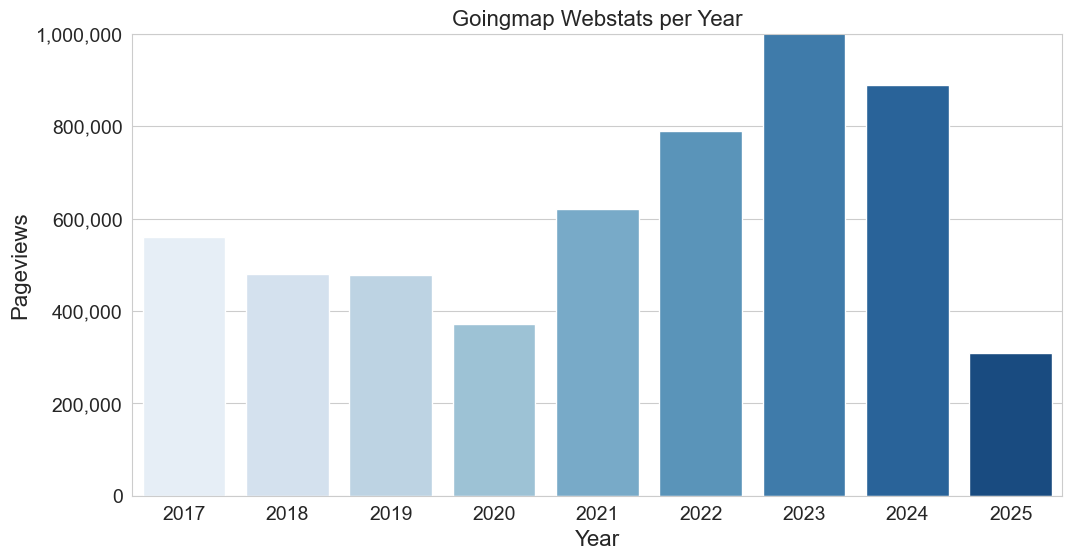

In [4]:
# plot webstats barchart
plt.figure(figsize=(12, 6))
sns.barplot(x='year', y='views', data=df_webstats, palette='Blues')
plt.gca().get_yaxis().set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
plt.title('Goingmap Webstats per Year', fontsize=16)
plt.xlabel('Year', fontsize=16)
plt.ylabel('Pageviews', fontsize=16)
plt.ylim(0, 1000000)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.show()

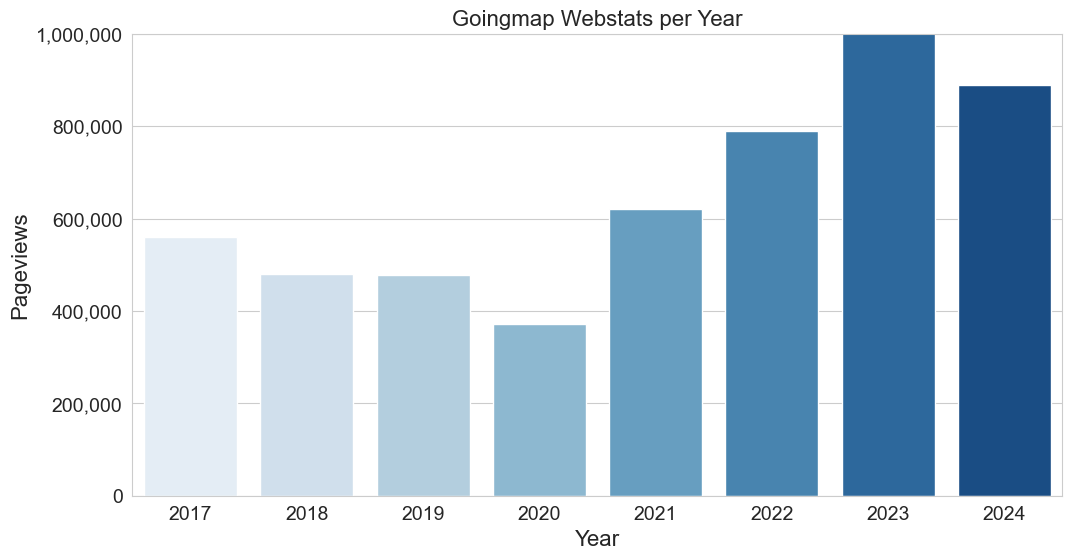

In [ ]:
# plot webstats barchart
plt.figure(figsize=(12, 6))
sns.barplot(x='year', y='views', data=df_webstats[df_webstats['year'] != 2025], palette='Blues')
plt.gca().get_yaxis().set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
plt.title('Goingmap Webstats per Year', fontsize=16)
plt.xlabel('Year', fontsize=16)
plt.ylabel('Pageviews', fontsize=16)
plt.ylim(0, 1000000)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.show()

In [ ]:
# set variables

sql_files = ["sql-001-001-hm-000020-000010-cheltenham_query_stick_readings.sql", 
             "sql-002-001-hm-000020-000010-cheltenham__query_reports.sql"]

calendar_files = [r'N:\GoingReportDatabase\2009 - 2024 BHA  Racing Calendars\2018 Calendar BHA\BHA MASTER 2018_Fixture_List.xlsx',
                  r'N:\GoingReportDatabase\2009 - 2024 BHA  Racing Calendars\2019 Calendar BHA\BHA MASTER 2019_Fixture_List.xlsx',
                  r'N:\GoingReportDatabase\2009 - 2024 BHA  Racing Calendars\2020 Calendar BHA\BHA MASTER 2020_Fixture_List.xlsx',
                  r'N:\GoingReportDatabase\2009 - 2024 BHA  Racing Calendars\2021 Calendar BHA\BHA MASTER 2021_Fixture_List.xlsx',
                  r'N:\GoingReportDatabase\2009 - 2024 BHA  Racing Calendars\2022 Calendar BHA\BHA MASTER 2022_Fixture_List.xlsx', 
                  r'N:\GoingReportDatabase\2009 - 2024 BHA  Racing Calendars\2023 Calendar BHA\BHA MASTER 2023_Fixture_List.xlsx',
                  r'N:\GoingReportDatabase\2009 - 2024 BHA  Racing Calendars\2024 Calendar BHA\BHA MASTER 2024_Fixture_List.xlsx',
                  r'N:\GoingReportDatabase\2009 - 2024 BHA  Racing Calendars\2025 Calendar BHA\BHA MASTER 2024_Fixture_List.xlsx']

In [ ]:
# set up functions

# database connection and data download

def fetch_data(sql_query_file):
        
    # establish a connection to the MySQL database
    connection = pymysql.connect(
        host="tthubdb-cluster-1.cluster-che9ka0taxng.eu-west-1.rds.amazonaws.com",
        user="hubview",
        password="v13whub_",
        database="tthub"
    )

    with open(sql_query_file, 'r') as file:
        sql_query = file.read()

    try:        
        # check the connection status
        connection.ping()

        # if the ping is successful, the connection is still active
        print("Database connection is active")
    
    except MySQLdb.Error as e:
        # If an error occurs, the connection is closed or lost
        print(f"Error: {e}")

    # Execute the SQL query
    try:    
        with connection.cursor() as cursor:
            cursor.execute(sql_query)

            # Get the field names from the cursor description
            field_names = [i[0] for i in cursor.description]
            # Fetch all data and return as a DataFrame
            return pd.DataFrame(cursor.fetchall(), columns=field_names)

    finally:
        # always close the database connection
        connection.close()


# BHA Calendar Data Import

In [ ]:
# extract turf data
df_cal = []

for index, file in enumerate(calendar_files):
    if os.path.exists(file):
        df = pd.read_excel(file, sheet_name='List', engine='openpyxl', parse_dates=["Date"])
        df['year'] = 2018 + index
        df['source'] = file
        df_cal.append(df)

df_cal = pd.concat(df_cal, ignore_index=True)
df_cal = df_cal[(~df_cal['Course'].isna())]
df_cal.columns = df_cal.columns.str.lower()

In [ ]:
# modify fields

# reformat course names
df_cal['course'] = df_cal['course'].str.lower().str.title()

# convert "Both" in the code column into "Mixed"
df_cal['code'] = df_cal['code'].replace('Both', 'Mixed')

# modify the Yarmouth entries and correct the AWT spelling where required
df_cal['course'] = df_cal['course'].replace('Yarmouth', 'Great Yarmouth')
df_cal['surface'] = df_cal['surface'].replace('Awt', 'AWT')

# adjust BHA calendar wrong entries
df_cal.loc[(df_cal['course'] == 'Chelmsford City') & (df_cal['surface'] == 'Turf'), 'surface'] = 'AWT'
df_cal.loc[(df_cal['course'] == 'Wolverhampton') & (df_cal['surface'] == 'Turf'), 'surface'] = 'AWT'
df_cal.loc[(df_cal['course']  == 'Great Yarmouth') & (df_cal['surface'] == 'AWT'), 'surface'] = 'Turf'
df_cal.loc[(df_cal['course']  == 'Doncaster') & (df_cal['surface'] == 'AWT'), 'surface'] = 'Turf'

# add month as number and as text
df_cal['month'] = df_cal['date'].dt.month.astype(int)
df_cal['month_txt'] = df_cal['date'].dt.strftime('%B')

# generate joinkeys
df_cal['joinkey'] = df_cal['date'].astype(str) + '_' + df_cal['course']

# determine declaration day
df_cal['declaration_date'] = df_cal['date'] - pd.Timedelta(days=2)
df_cal['joinkey_declaration'] = df_cal['declaration_date'].astype(str) + '_' + df_cal['course']


In [ ]:
# check result
df_cal = df_cal[df_cal['course'].isin(['Cheltenham'])]
df_cal.groupby(['code', 'year']).agg({'date': 'nunique'}).reset_index()

# Stick Readings

## Data Import

In [ ]:
# import the data
file_path = 'dat-001-002-hm-000020-000010-df_sre.csv'

if not os.path.exists(file_path):
    # file does not exist, fetch the data
    print("downloading data from AWS")
    df_sre = fetch_data(sql_files[0])
    df_sre.to_csv(file_path, index=False)
else:
    # File exists, import the data
    print("importing csv file", file_path)
    df_sre = pd.read_csv(file_path)
    df_sre['sr_created_at'] = pd.to_datetime(df_sre['sr_created_at'], format='%Y-%m-%d %H:%M:%S')

print(len(df_sre))

In [ ]:
# modify data types
df_sre['date'] = df_sre['sr_created_at'].dt.date
df_sre['date_cat'] = df_sre['date'].astype('str').astype('category')
df_sre['year'] = df_sre['sr_created_at'].dt.year
df_sre['year_cat'] = df_sre['year'].astype('int').astype('category')
df_sre['month'] = df_sre['sr_created_at'].dt.month
df_sre['day'] = df_sre['sr_created_at'].dt.day
df_sre['day_cat'] = df_sre['day'].astype('int').astype('category')
df_sre[['sr_index', 'sr_shear', 'sr_penetration']] = df_sre[['sr_index', 'sr_shear', 'sr_penetration']].astype(float)

# rename columns
df_sre['course'] = df_sre['co_name'].str.lower().str.title()
df_sre['joinkey'] = df_sre['date'].astype(str) + '_' + df_sre['course']

# adjust map names
df_sre['ma_label'] = df_sre['ma_label'].replace('NEW ', 'NEW')
df_sre['ma_label'] = df_sre['ma_label'].replace('New', 'NEW')
df_sre['ma_label'] = df_sre['ma_label'].replace('ALL Maps', 'All Maps')

# reformat values
df_sre[['sr_index', 'sr_penetration', 'sr_shear']] = df_sre[['sr_index', 'sr_penetration', 'sr_shear']].astype(float)

# remove invalid data
df_sre['data_type'] = 'data point'
df_sre.loc[(df_sre['sr_index'] == 0) | (df_sre['sr_shear'] == 15), 'data_type'] = 'error'
df_sre = df_sre[df_sre['data_type'] == 'data point']

# flag racedays by checking if the df_sre joinkey occurs in df_cal
df_sre['raceday'] = df_sre['joinkey'].isin(df_cal['joinkey'])
df_sre['declaration'] = df_sre['joinkey'].isin(df_cal['joinkey_declaration'])

## Basic Stats

In [ ]:
# basic stats stick readings - grouped by year
df_sre.groupby(['year']).agg({'date': 'count', 'sr_index': ['min', 'max', 'mean', 'std'], 'sr_shear': ['min', 'max', 'mean', 'std'], 'sr_penetration': ['min', 'max', 'mean', 'std']})


In [ ]:
# basic stats stick readings - grouped by map and year
df_sre.groupby(['year', 'ma_label']).agg({'date': 'count', 'sr_index': ['min', 'max', 'mean', 'std'], 'sr_shear': ['min', 'max', 'mean', 'std'], 'sr_penetration': ['min', 'max', 'mean', 'std']})

# Going Reports

## Data Import

In [ ]:
# import the data
file_path = 'dat-002-002-hm-000020-000010-df_gre.csv'

if not os.path.exists(file_path):
    # file does not exist, fetch the data
    print("downloading data from AWS")
    df_gre = fetch_data(sql_files[1])
    df_gre.to_csv(file_path, index=False)
else:
    # File exists, import the data
    print("importing csv file", file_path)
    df_gre = pd.read_csv(file_path)
    df_gre['created_at_gr'] = pd.to_datetime(df_gre['created_at_gr'], format='%Y-%m-%d %H:%M:%S')

len(df_gre)

In [ ]:
# modify data types
df_gre['date'] = df_gre['created_at_gr'].dt.date
df_gre['year'] = df_gre['created_at_gr'].dt.year
df_gre['year_cat'] = df_gre['year'].astype('int').astype('category')

# reformat course names
df_gre['course'] = df_gre['course'].str.lower().str.title()
df_gre['joinkey'] = df_gre['date'].astype(str) + '_' + df_gre['course']

# flag racedays by checking if the df_sre joinkey occurs in df_cal
df_gre['raceday'] = df_gre['joinkey'].isin(df_cal['joinkey'])
df_gre['declaration'] = df_gre['joinkey'].isin(df_cal['joinkey_declaration'])

# flag reports with stick reading data
df_gre['in_df_sre'] = df_gre['joinkey'].isin(df_sre['joinkey']).astype(int)

In [ ]:
# process all text in the column 'stick_comments' to lower case
df_gre['stick_comments'] = df_gre['stick_comments'].str.lower()

# add a field to the df_gre_turf_rpt dataframe to flag the occurrence of 'readings' in the 'stick_comments' column
df_gre['fl_time'] = df_gre['stick_comments'].str.contains('[0-2][0-9]:[0-5][0-9]', regex=True).fillna(False).astype(int)
df_gre['fl_reading_value'] = df_gre['stick_comments'].str.contains('[0-9]\.[0-9]', regex=True).fillna(False).astype(int)

print(len(df_gre))
print(df_gre.groupby(['fl_reading_value', 'fl_time']).size().reset_index(name='count'))


In [ ]:
# basic stats
df_gre.groupby(['year']).agg({'date': 'count', 'fl_time': 'sum', 'fl_reading_value': 'sum'})

In [ ]:
# create a category for the reporting, if fl_reading_value is 0, then 'not reported', if fl_reading_value is 1, then 'reported', if fl_reading_value is 1 and in_df_sre = 1, then 'reported and uploaded'
df_gre['reporting'] = np.where((df_gre['in_df_sre'] == 1), 'data uploaded',
                                      np.where(((df_gre['fl_reading_value'] == 1)), 'going value reported',
                                               'going value not reported'))
# Set the order for the categories
category_order = ['going value not reported', 'going value reported', 'data uploaded']

# Convert the 'reporting' column to a categorical data type with the specified order
df_gre['reporting'] = pd.Categorical(df_gre['reporting'], categories=category_order, ordered=True)

# Graphs

In [ ]:
# Plot the reports per year

plt.figure(figsize=(18, 6))
sns.histplot(data=df_gre[(df_gre['raceday'] == 1) | (df_gre['declaration'] == 1)], x='year_cat', hue='reporting', multiple="stack")

# set title and rotate x-axis labels
plt.title('Declaration and Raceday Reporting for Cheltenham')
plt.xticks(rotation=90)

plt.show()

In [ ]:
# index main
plt.figure(figsize=(12, 6))
sns.countplot(x='year_cat', data=df_sre, palette='Blues')

plt.title('Cheltenham Overall Stick Readings per Year', fontsize=16)
plt.xlabel('Year', fontsize=16)
plt.ylabel('Count', fontsize=16)

# increase size of x-axis labels
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.show()

## Boxplots per Year

### Index

In [ ]:
# index main
plt.figure(figsize=(12, 6))
sns.boxplot(x='year_cat', y="sr_index", data=df_sre, palette='Blues')

plt.title('Cheltenham Overall Measured Index per Year', fontsize=16)
plt.xlabel('Year', fontsize=16)
plt.ylabel('Count', fontsize=16)

# increase size of x-axis labels
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# set x-axis limits
plt.ylim(1, 14)

plt.show()

### Penetration

In [ ]:
# penetration main
plt.figure(figsize=(12, 6))
sns.boxplot(x='year_cat', y="sr_penetration", data=df_sre, palette='Blues')

plt.title('Cheltenham Overall Measured Penetration per Year', fontsize=16)
plt.xlabel('Year', fontsize=16)
plt.ylabel('Count', fontsize=16)

# increase size of x-axis labels
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# set x-axis limits
plt.ylim(1, 14)

plt.show()

### Shear

In [ ]:
# shear main
plt.figure(figsize=(12, 6))
sns.boxplot(x='year_cat', y="sr_shear", data=df_sre, palette='Blues')

plt.title('Cheltenham Overall Measured Shear per Year', fontsize=16)
plt.xlabel('Year', fontsize=16)
plt.ylabel('Count', fontsize=16)

# increase size of x-axis labels
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# set x-axis limits
plt.ylim(1, 14)

plt.show()

## Facet Charts per Year

### Index

In [ ]:
# Data Overview - Index
ax = sns.catplot(data=df_sre[((df_sre['raceday'] == 1) | (df_sre['declaration'] == 1)) & (df_sre['year'] > 2018 ) & (df_sre['month'] == 3)], y='sr_index', x='day_cat',
col='year', kind = 'box', col_wrap=6, height=12, aspect=1, palette='Blues_d')
ax.set_axis_labels("", "Count")
ax.set_titles("Index {col_name}", size=32)

### Penetration

In [ ]:
# Data Overview - Penetration
ax = sns.catplot(data=df_sre[((df_sre['raceday'] == 1) | (df_sre['declaration'] == 1)) & (df_sre['year'] > 2020 ) & (df_sre['month'] == 3)], y='sr_penetration', x='day_cat',
col='year', kind = 'box', col_wrap=6, height=12, aspect=1, palette='Blues_d')
ax.set_axis_labels("", "Count")
ax.set_titles("Index {col_name}", size=32)

### Shear

In [ ]:
# Data Overview - Shear
ax = sns.catplot(data=df_sre[((df_sre['raceday'] == 1) | (df_sre['declaration'] == 1)) & (df_sre['year'] > 2020 ) & (df_sre['month'] == 3)], y='sr_shear', x='day_cat',
col='year', kind = 'box', col_wrap=6, height=12, aspect=1, palette='Blues_d')
ax.set_axis_labels("", "Count")
ax.set_titles("Index {col_name}", size=32)

In [ ]:
# scatter per year
g = sns.FacetGrid(df_sre[((df_sre['raceday'] == 1) | (df_sre['declaration'] == 1)) & (df_sre['year'] > 2018 ) & (df_sre['month'] == 3)], col="year", margin_titles=True, height=4, aspect=1)
g.map(sns.scatterplot, "sr_shear", "sr_penetration")
g.set_axis_labels("Shear", "Penetration")


# Soil Moisture

## Data Import

In [ ]:
# import moisture data

csv_files = [file for file in os.listdir(r'.\003-sm') if file.startswith("Cheltenham")]

dfs = []
for file in csv_files:
    file_path = os.path.join(r'.\003-sm', file)
    df = pd.read_csv(file_path, skiprows= 37)
    df["file_name"] = file
    dfs.append(df)

df_som = pd.concat(dfs, ignore_index=True)


In [ ]:
# clean data
df_som = df_som.rename(columns={'Sample': 'id', 'Plot': 'track', '% Vol': 'soil_moisture'})
df_som = df_som.rename(columns=lambda x: x.lower())
df_som = df_som[['time', 'id', 'track', 'soil_moisture', 'file_name']]

In [ ]:
# extract date from filename
df_som['collect_date'] = pd.to_datetime(df_som['file_name'].str.extract(r'(\d{1,2}\w{2} \w+ \d{2})')[0], format='%dth %B %y')
df_som['collect_date_cat'] = df_som['collect_date'].dt.strftime('%Y-%m-%d').astype('category')

# reformat timestamp
df_som['timestamp'] = pd.to_datetime(df_som['time'], format='mixed')

df_som.info()

## Table

In [ ]:
# basic moisture stats
df_som_sum = df_som.groupby(['collect_date']).agg({'soil_moisture': ['count', 'min', 'mean', 'max']}).reset_index()
# df_som_sum.to_csv("dat-003-001-hm-000020-000010-soil_moisture.csv", index=False)
df_som_sum['collect_date'] = pd.to_datetime(df_som_sum['collect_date']).dt.date
df_som_sum['collect_date'][0]

## Graph

In [ ]:
df_sre_som = df_sre[(df_sre['date_cat'].isin(["2024-02-27", "2024-03-05", "2024-03-12", "2024-03-13", "2024-03-14", "2024-03-15"]))].groupby(['date']).agg({'sr_index': ['min', 'max', 'mean', 'std'], 'sr_shear': ['min', 'max', 'mean', 'std'], 'sr_penetration': ['min', 'max', 'mean', 'std']}).reset_index()
df_sre_som['date'][0]

In [ ]:
df_sre_som_sum = df_sre_som.merge(df_som_sum, left_on='date', right_on='collect_date', how='inner')
df_sre_som_sum

In [ ]:
# scatter index moisture
plt.figure(figsize=(6, 6))
sns.scatterplot(x=("soil_moisture", "mean"), y=("sr_index", "mean"), hue = "date", data=df_sre_som_sum, palette="Blues_d")

plt.title('Cheltenham Index versus Moisture March 2024', fontsize=16)
plt.xlabel('Index', fontsize=16)
plt.ylabel('Soil Moisture', fontsize=16)

# increase size of x-axis labels and rotate them by 90 degrees
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# set x-axis limits
plt.ylim(3, 6)

plt.show()

In [ ]:
# index
plt.figure(figsize=(6, 6))
sns.boxplot(x="date", y="sr_index", data=df_sre[(df_sre['date_cat'].isin(["2024-02-27", "2024-03-05", "2024-03-12", "2024-03-13", "2024-03-14", "2024-03-15"]))].sort_values(by='sr_created_at', ascending=True), palette="Blues_d")

plt.title('Cheltenham Index March 2024', fontsize=16)
plt.xlabel('Date', fontsize=16)
plt.ylabel('Index', fontsize=16)

# increase size of x-axis labels and rotate them by 90 degrees
plt.xticks(fontsize=14, rotation=90)
plt.yticks(fontsize=14)

# set x-axis limits
plt.ylim(1, 14)

plt.show()

In [ ]:
# soil moisture
plt.figure(figsize=(6, 6))
sns.boxplot(x="collect_date_cat", y="soil_moisture", data=df_som, palette="Blues_d")

plt.title('Cheltenham Soil Moisture March 2024', fontsize=16)
plt.xlabel('Date', fontsize=16)
plt.ylabel('Soil Moisture (%)', fontsize=16)

# increase size of x-axis labels and rotate them by 90 degrees
plt.xticks(fontsize=14, rotation=90)
plt.yticks(fontsize=14)

plt.show()